# 공유자전거 대여 수요 예측 — 회귀 미니프로젝트

**모듈 1 · Day 1 · 8교시 / TODO Notebook**

- 데이터: UCI Bike Sharing Dataset의 `hour.csv`
- 예측 대상: 시간당 총 대여량 `cnt`
- 개발 방법: **공통 코드 실행 → TODO 직접 구현 → CP-01~08 결과 확인**
- 이 Notebook은 *미완성 실습 템플릿*입니다. `...` 부분을 완성하기 전에는 일부 셀이 오류를 발생할 수 있습니다.
- 실습 안내 교안과 함께 사용합니다. TODO의 정답이나 모델 성능값은 제공하지 않습니다.
- VS Code에서 `ai-mini-projects/.venv`의 Python 3.11 커널을 선택합니다.
- **작업 폴더**: `mini-project-01/code/` (데이터 상대경로 `../data/hour.csv`)

> **주의**: Test 데이터는 최종 ⑧교시 평가에서만 사용합니다. 모든 코드는 ①부터 순서대로 실행합니다.

---
## ① 데이터 탐색 및 시각화 — CP-01
**목표:** 데이터 구조·품질을 확인하고 시간대별 평균 대여량을 시각화합니다.

### ①-1. 데이터 불러오기 — 공통 코드

In [307]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_PATH = "../data/hour.csv"
df = pd.read_csv(DATA_PATH)
print("데이터 로딩 완료")

데이터 로딩 완료


### ①-2. 데이터 구조 및 품질 확인 — TODO

In [308]:
# TODO 1-1. 데이터의 행·열 개수와 자료형을 확인합니다.
# 힌트: shape, dtypes

# 행과 열 개수 출력
print("=== 데이터 크기 ===")
print(f"행 개수: {df.shape[0]}")
print(f"열 개수: {df.shape[1]}")

# 컬럼명과 자료형 출력
print("\n=== 컬럼명과 자료형 ===")
print(df.dtypes)


=== 데이터 크기 ===
행 개수: 17379
열 개수: 17

=== 컬럼명과 자료형 ===
instant         int64
dteday            str
season          int64
yr              int64
mnth            int64
hr              int64
holiday         int64
weekday         int64
workingday      int64
weathersit      int64
temp          float64
atemp         float64
hum           float64
windspeed     float64
casual          int64
registered      int64
cnt             int64
dtype: object


In [309]:
# TODO 1-2. 처음 5개 행과 기초 통계량을 확인합니다.
# 힌트: head(), describe()

# 처음 5개 행 출력
print("\n=== 처음 5개 행 ===")
print(df.head())

# 주요 컬럼의 기초 통계량
print("\n=== 기초 통계량 ===")
print(df.describe())



=== 처음 5개 행 ===
   instant      dteday  season  yr  mnth  hr  holiday  weekday  workingday  \
0        1  2011-01-01       1   0     1   0        0        6           0   
1        2  2011-01-01       1   0     1   1        0        6           0   
2        3  2011-01-01       1   0     1   2        0        6           0   
3        4  2011-01-01       1   0     1   3        0        6           0   
4        5  2011-01-01       1   0     1   4        0        6           0   

   weathersit  temp   atemp   hum  windspeed  casual  registered  cnt  
0           1  0.24  0.2879  0.81        0.0       3          13   16  
1           1  0.22  0.2727  0.80        0.0       8          32   40  
2           1  0.22  0.2727  0.80        0.0       5          27   32  
3           1  0.24  0.2879  0.75        0.0       3          10   13  
4           1  0.24  0.2879  0.75        0.0       0           1    1  

=== 기초 통계량 ===
          instant        season            yr          mnth       

In [310]:
# TODO 1-3. 결측값과 중복 행 개수를 확인합니다.
# 힌트: isna().sum(), duplicated().sum()
...

# 컬럼별 결측값 개수 확인
print("=== 결측값 확인 ===")
print(df.isnull().sum())
print(df.isna().sum())

# 전체 결측값 개수
print("\n전체 결측값 개수:", df.isnull().sum().sum())


=== 결측값 확인 ===
instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64
instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

전체 결측값 개수: 0


In [311]:
# 중복 행 개수 확인
print("=== 중복 행 확인 ===")
print("중복 행 개수:", df.duplicated().sum())

# 중복 행 출력
print("\n중복 행 데이터:")
print(df[df.duplicated()])


=== 중복 행 확인 ===
중복 행 개수: 0

중복 행 데이터:
Empty DataFrame
Columns: [instant, dteday, season, yr, mnth, hr, holiday, weekday, workingday, weathersit, temp, atemp, hum, windspeed, casual, registered, cnt]
Index: []


### ①-3. 대여량 분포 및 시간대별 분석 — TODO

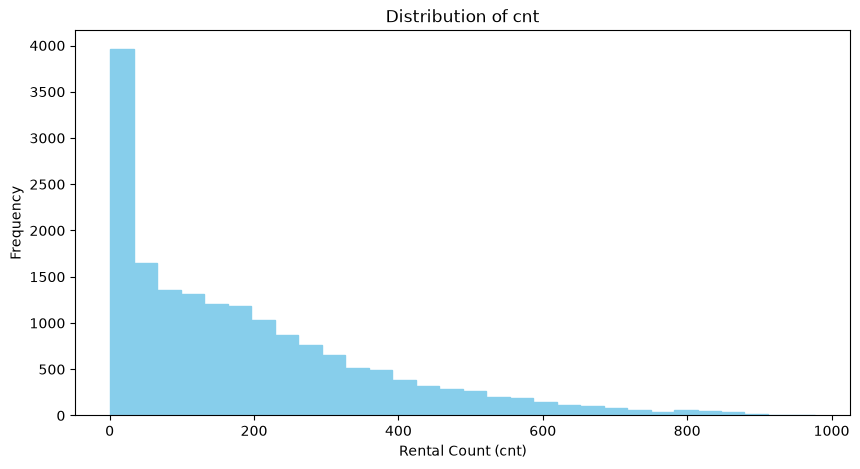

In [312]:
# TODO 1-4. cnt의 분포를 히스토그램으로 시각화합니다.
# 힌트: plt.hist(), plt.xlabel(), plt.ylabel(), plt.show()

plt.figure(figsize=(10, 5))

plt.hist(df['cnt'], bins=30, color='skyblue', edgecolor='skyblue')

plt.xlabel('Rental Count (cnt)')
plt.ylabel('Frequency')
plt.title('Distribution of cnt')

plt.show()

In [313]:
# TODO 1-5. 시간대(hr)별 평균 대여량을 계산합니다.
# 힌트: groupby("hr")["cnt"].mean()

hourly_mean = df.groupby('hr')['cnt'].mean()

print("=== 시간대별 평균 대여량 ===")
print(hourly_mean)

=== 시간대별 평균 대여량 ===
hr
0      53.898072
1      33.375691
2      22.869930
3      11.727403
4       6.352941
5      19.889819
6      76.044138
7     212.064649
8     359.011004
9     219.309491
10    173.668501
11    208.143054
12    253.315934
13    253.661180
14    240.949246
15    251.233196
16    311.983562
17    461.452055
18    425.510989
19    311.523352
20    226.030220
21    172.314560
22    131.335165
23     87.831044
Name: cnt, dtype: float64


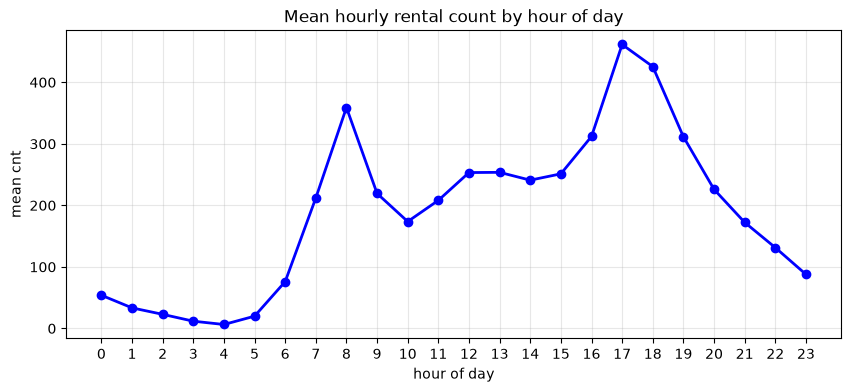

In [314]:
# [공통] 그래프 기본 설정
plt.figure(figsize=(10, 4))

# TODO 1-6. 시간대별 평균 대여량 선 그래프를 그립니다.
# 힌트: plt.plot(hourly_mean.index, hourly_mean.values, marker="o")

plt.plot(hourly_mean.index, hourly_mean.values, marker='o', color='blue', linewidth=2)

plt.xticks(range(0, 24))
plt.xlabel("hour of day")
plt.ylabel("mean cnt")
plt.title("Mean hourly rental count by hour of day")
plt.grid(alpha=0.3)
plt.show()

**[CP-01] 완료 기준:** 데이터 크기·결측값·중복 여부를 확인하고, `cnt` 분포와 시간대별 평균 대여량 그래프를 완성합니다.

**선택 심화:** 평일과 주말의 시간대별 대여량을 비교해 봅니다.

---
## ② 입력 특성 선택 및 상관관계 분석 — CP-02
**목표:** 날짜별 데이터 분할, 누수 확인, Train 상관관계 분석을 마치고 입력 특성을 결정합니다.

### ②-1. 시간 순서 분할 — 일부 공통 코드 + TODO

In [315]:
# [공통] 날짜 변환 및 시간 순서 정렬
df["dteday"] = pd.to_datetime(df["dteday"])
df = df.sort_values(["dteday", "hr"]).reset_index(drop=True)

dates = np.sort(df["dteday"].unique())
n_dates = len(dates)

# TODO 2-1. 날짜 기준 Train 약 70%, Validation 약 15%, 나머지 Test로 분할합니다.
# 같은 날짜의 행은 반드시 같은 집합에 포함되어야 합니다.
# 힌트: int(), 날짜 배열 슬라이싱, .isin()
n_train = int(n_dates * 0.70)
n_valid = int(n_dates * 0.85)

train_dates = dates[:n_train]
valid_dates = dates[n_train:n_valid]
test_dates = dates[n_valid:]

train_df = df[df["dteday"].isin(train_dates)].copy()
valid_df = df[df["dteday"].isin(valid_dates)].copy()
test_df = df[df["dteday"].isin(test_dates)].copy()

# 결과 확인
print("=== 데이터 분할 결과 ===")

print(f"전체 날짜 수: {n_dates}")
print(f"Train 날짜 수: {len(train_dates)}")
print(f"Validation 날짜 수: {len(valid_dates)}")
print(f"Test 날짜 수: {len(test_dates)}")

print("\n=== 각 데이터 행 개수 ===")
print(f"Train: {len(train_df)}행")
print(f"Validation: {len(valid_df)}행")
print(f"Test: {len(test_df)}행")

print("\n=== 날짜 범위 ===")
print(f"Train: {train_df['dteday'].min()} ~ {train_df['dteday'].max()}")
print(f"Validation: {valid_df['dteday'].min()} ~ {valid_df['dteday'].max()}")
print(f"Test: {test_df['dteday'].min()} ~ {test_df['dteday'].max()}")

=== 데이터 분할 결과 ===
전체 날짜 수: 731
Train 날짜 수: 511
Validation 날짜 수: 110
Test 날짜 수: 110

=== 각 데이터 행 개수 ===
Train: 12139행
Validation: 2640행
Test: 2600행

=== 날짜 범위 ===
Train: 2011-01-01 00:00:00 ~ 2012-05-25 00:00:00
Validation: 2012-05-26 00:00:00 ~ 2012-09-12 00:00:00
Test: 2012-09-13 00:00:00 ~ 2012-12-31 00:00:00


In [316]:
# [공통] 분할 범위 점검
for name, part in [
    ("Train", train_df),
    ("Validation", valid_df),
    ("Test", test_df),
]:
    print(name, part.shape)
    print(part["dteday"].min(), "~", part["dteday"].max())

Train (12139, 17)
2011-01-01 00:00:00 ~ 2012-05-25 00:00:00
Validation (2640, 17)
2012-05-26 00:00:00 ~ 2012-09-12 00:00:00
Test (2600, 17)
2012-09-13 00:00:00 ~ 2012-12-31 00:00:00


### ②-2. 데이터 누수 확인 — TODO

In [317]:
# TODO 2-2. casual + registered == cnt가 모든 행에서 성립하는지 확인합니다.
# 힌트: 비교식과 .all()

same = (df["casual"] + df["registered"] == df["cnt"]).all()
print("데이터 관계 확인:", same)

# TODO (추가 확인). casual, registered, cnt의 상관관계를 비교해 봅니다.
...

데이터 관계 확인: True


Ellipsis

### ②-3. 상관관계 분석 — TODO

In [318]:
# [공통] 분석에 사용할 컬럼
corr_cols = ["temp", "atemp", "hum", "windspeed", "cnt"]

# TODO 2-3. Train 데이터로만 상관계수를 계산합니다.
# 힌트: train_df[corr_cols].corr()

corr = train_df[corr_cols].corr()
display(corr.round(3))

,temp,atemp,hum,windspeed,cnt
temp,1.000,0.992,-0.016,-0.015,0.398
atemp,0.992,1.000,-0.000,-0.058,0.398
hum,-0.016,-0.000,1.000,-0.297,-0.301
windspeed,-0.015,-0.058,-0.297,1.000,0.094
cnt,0.398,0.398,-0.301,0.094,1.000


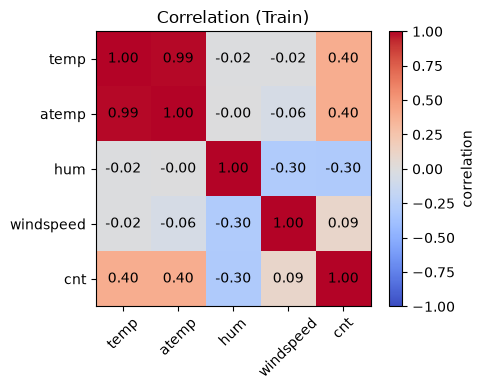

In [319]:
# [공통] 상관관계 시각화 기본 구조
plt.figure(figsize=(5, 4))

# TODO 2-4. 상관관계 행렬을 히트맵으로 시각화합니다.
# 힌트: plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
#       plt.colorbar(label="correlation")
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="correlation")

# 각 셀에 상관계수 표시
#for i in range(len(corr_cols)):
#    for j in range(len(corr_cols)):
for i in range(corr.shape[0]):
    for j in range(corr.shape[1]):
        plt.text(
            j, i,
            f"{corr.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            color="black"
        )

plt.xticks(range(len(corr_cols)), corr_cols, rotation=45)
plt.yticks(range(len(corr_cols)), corr_cols)
plt.title("Correlation (Train)")
plt.tight_layout()
plt.show()

### ②-4. 입력 특성 선택 — TODO (핵심 의사결정 ①)

In [320]:
# TODO 2-5. 모델에 사용할 입력 컬럼을 선택합니다.
# 다음을 검토하세요: 타깃 cnt, 대여 후 집계값, 행 식별자, 유사한 정보를 가진 컬럼.
# 목록과 제외 이유는 안내 교안에 따라 스스로 결정합니다.
FEATURES = [
    # 사용할 특성명을 문자열로 작성하세요.
    "season",
    "yr",
    "mnth",
    "hr",
    "holiday",
    "weekday",
    "workingday",
    "weathersit",
    "temp",
    "atemp",
    "hum",
    "windspeed"
]
TARGET = "cnt"

print("사용할 특성:", FEATURES)
print("예측 대상:", TARGET)

사용할 특성: ['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed']
예측 대상: cnt


In [321]:
# [공통] 입력 X와 정답 y 분리
X_train = train_df[FEATURES].copy()
X_valid = valid_df[FEATURES].copy()
X_test = test_df[FEATURES].copy()

y_train = train_df[TARGET]
y_valid = valid_df[TARGET]
y_test = test_df[TARGET]

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_valid.shape, y_valid.shape)
print("Test:", X_test.shape, y_test.shape)

Train: (12139, 12) (12139,)
Validation: (2640, 12) (2640,)
Test: (2600, 12) (2600,)


**[CP-02] 완료 기준 :** 분할한 데이터의 기간·크기를 확인하고, 누수 검증 결과·Train 상관관계 표·선택한 `FEATURES`를 설명할 수 있습니다.

In [322]:
print("=== 데이터 분리 결과 ===")

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_valid:", X_valid.shape)
print("y_valid:", y_valid.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

=== 데이터 분리 결과 ===
X_train: (12139, 12)
y_train: (12139,)
X_valid: (2640, 12)
y_valid: (2640,)
X_test: (2600, 12)
y_test: (2600,)


---
## ③ 특성공학 및 데이터 전처리 — CP-03
**목표:** 출퇴근 시간 특성을 생성하고, 인코딩·표준화·전처리 결합을 구현합니다.

### ③-1. 출퇴근 특성 생성 — TODO

In [323]:
# [공통] 실습에서 사용할 출퇴근 시간 가정
COMMUTE_HOURS = [7, 8, 9, 17, 18, 19]


def add_commute_feature(X):
    """기존 hr와 workingday로 is_commute_hour 특성을 추가합니다."""
    X = X.copy()

    # TODO 3-1. workingday == 1이면서 hr이 COMMUTE_HOURS에 있으면 1, 아니면 0
    # 힌트: isin(), &, astype(int)
    X["is_commute_hour"] = (
        (X["workingday"] == 1) &
        (X["hr"].isin(COMMUTE_HOURS))
    ).astype(int)

    return X

# [공통] 모든 집합에 같은 특성공학 함수 적용
X_train = add_commute_feature(X_train)
X_valid = add_commute_feature(X_valid)
X_test = add_commute_feature(X_test)

In [324]:
# [공통] 간단 검증 — 기대 결과는 [1, 0, 0, 1]
check = pd.DataFrame({"hr": [8, 8, 14, 18], "workingday": [1, 0, 1, 1]})
print(add_commute_feature(check))

   hr  workingday  is_commute_hour
0   8           1                1
1   8           0                0
2  14           1                0
3  18           1                1


### ③-2. 특성 유형 구분 및 ColumnTransformer — TODO

In [325]:
# TODO 3-2. 선택한 입력 특성을 세 유형으로 구분합니다.
# 범주형(One-Hot 인코딩), 수치형(StandardScaler), 이진형(그대로 사용)
# ②교시 FEATURES와 새로 만든 is_commute_hour가 모두 포함되어야 합니다.
categorical_features = [
    "yr",
    "season",
    "mnth",
    "weekday",
    "weathersit"
]
numeric_features = [
    "temp",
    "atemp",
    "hum",
    "windspeed",
    "hr"
]
binary_features = [
    "holiday",
    "workingday",
    "is_commute_hour"
]

# [공통] 중복/누락 없는지 확인
all_features = categorical_features + numeric_features + binary_features
assert len(all_features) == len(set(all_features)), "특성 목록이 중복됩니다."
# print(all_features)
# print(X_train.columns)
assert set(all_features) == set(X_train.columns), "분류되지 않은 컬럼이 있습니다."

print("범주형:", categorical_features)
print("수치형:", numeric_features)
print("이진형:", binary_features)

범주형: ['yr', 'season', 'mnth', 'weekday', 'weathersit']
수치형: ['temp', 'atemp', 'hum', 'windspeed', 'hr']
이진형: ['holiday', 'workingday', 'is_commute_hour']


In [326]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

def make_preprocessor():
    # TODO 3-3. 다음 세 변환을 ColumnTransformer로 결합합니다.
    # 범주형: OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    # 수치형: StandardScaler()
    # 이진형: "passthrough"
    preprocessor = ColumnTransformer(
        transformers=[
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
            ("num", StandardScaler(), numeric_features),
            ("bin", "passthrough", binary_features)
        ]
    )

    return preprocessor

# [공통] 전처리 객체 생성
preprocessor = make_preprocessor()

### ③-3. 전처리 결과 확인 — 공통 코드

In [327]:
# Train에서만 전처리 기준을 학습합니다.
Xt_train = preprocessor.fit_transform(X_train)
Xt_valid = preprocessor.transform(X_valid)

print("변환 전 Train:", X_train.shape, "→ 변환 후:", Xt_train.shape)
print("변환 전 Valid:", X_valid.shape, "→ 변환 후:", Xt_valid.shape)

변환 전 Train: (12139, 13) → 변환 후: (12139, 37)
변환 전 Valid: (2640, 13) → 변환 후: (2640, 37)


**[CP-03] 완료 기준:** `is_commute_hour`를 생성하고 `make_preprocessor()`가 정상 실행되며, Train/Validation 변환 결과를 출력합니다.

**선택 심화:** 시간대의 주기성을 반영하는 특성을 추가해 봅니다.

---
## ④ 기준 모델 및 선형회귀 — CP-04
**목표:** DummyRegressor·LinearRegression을 학습하고 MAE·RMSE·R² 공통 평가 함수를 구현합니다.

### ④-1. 모델 구성과 학습 — TODO

In [328]:
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression

# TODO 4-1. 전처리 + DummyRegressor(strategy="mean") Pipeline 구현
dummy_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DummyRegressor(strategy="mean"))
])

# TODO 4-2. 전처리 + LinearRegression() Pipeline 구현
linear_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

# [공통] 모델 학습
dummy_model.fit(X_train, y_train)
linear_model.fit(X_train, y_train)
print("학습 완료")

학습 완료


### ④-2. 평가 함수 — TODO / 결과 정리 함수 — 공통

In [329]:
from sklearn.metrics import (
    mean_absolute_error,
    root_mean_squared_error,
    r2_score,
)


def evaluate_regression(model, X, y):
    """MAE, RMSE, R2 딕셔너리를 반환합니다."""
    # TODO 4-3. model.predict(X)로 예측하고 세 지표를 계산합니다.
    pred = model.predict(X)

    return {
        "MAE": mean_absolute_error(y, pred),
        "RMSE": root_mean_squared_error(y, pred),
        "R2": r2_score(y, pred),
    }


def summarize(name, model):
    """Train·Validation 평가를 한 행으로 정리합니다 (공통)."""
    tr = evaluate_regression(model, X_train, y_train)
    va = evaluate_regression(model, X_valid, y_valid)
    return {
        "Model": name,
        "Train MAE": tr["MAE"],
        "Train RMSE": tr["RMSE"],
        "Train R2": tr["R2"],
        "Valid MAE": va["MAE"],
        "Valid RMSE": va["RMSE"],
        "Valid R2": va["R2"],
    }

In [330]:
# [공통] 이후 교시에서 결과를 누적할 리스트
results = []
results.append(summarize("DummyRegressor", dummy_model))
results.append(summarize("LinearRegression", linear_model))

# TODO 4-4. 두 모델의 성능을 DataFrame으로 비교합니다.
# 힌트: pd.DataFrame(results).round(3)
pd.DataFrame(results).round(3)

,Model,Train MAE,Train RMSE,Train R2,Valid MAE,Valid RMSE,Valid R2
0,DummyRegressor,119.572,152.400,0.000,194.518,254.607,-0.296
1,LinearRegression,68.195,89.277,0.657,114.982,145.140,0.579


**[CP-04] 완료 기준:** 두 모델을 학습하고 공통 평가 함수로 Train·Validation 성능을 표로 비교합니다.

---
## ⑤ Decision Tree 모델 개선 — CP-05
**목표:** `max_depth`를 바꿔 학습·검증 MAE를 비교하고 그래프로 표현합니다.

### ⑤-1. 깊이별 모델 학습 — TODO

In [331]:
from sklearn.tree import DecisionTreeRegressor

# [공통] 실험 설정 및 저장 구조
depths = [3, 6, 12]
tree_models = {}
tree_results = []

# TODO 5-1~5-3. 각 깊이별 Pipeline 생성·학습·평가 결과 수집
for d in depths:
    # TODO 5-1. 전처리 + DecisionTreeRegressor(max_depth=d, random_state=42)
    model = Pipeline([
        ("preprocessor", preprocessor),
        ("model", DecisionTreeRegressor(max_depth=d, random_state=42))
    ])

    # TODO 5-2. 모델 학습
    model.fit(X_train, y_train)

    # [공통] 학습한 모델 보관
    tree_models[d] = model

    # TODO 5-3. summarize()로 성능 결과 수집
    row = summarize(f"DecisionTree_depth_{d}", model)
    tree_results.append(row)
    results.append(row)

# [공통] 결과 정리
tree_df = pd.DataFrame(tree_results)
tree_df["max_depth"] = depths
display(tree_df.round(3))

,Model,Train MAE,Train RMSE,Train R2,Valid MAE,Valid RMSE,Valid R2,max_depth
0,DecisionTree_depth_3,68.890,100.091,0.569,114.696,166.986,0.442,3
1,DecisionTree_depth_6,46.571,72.137,0.776,80.660,117.070,0.726,6
2,DecisionTree_depth_12,17.479,30.397,0.960,55.748,85.501,0.854,12


### ⑤-2. 모델 복잡도와 오차 시각화 — TODO

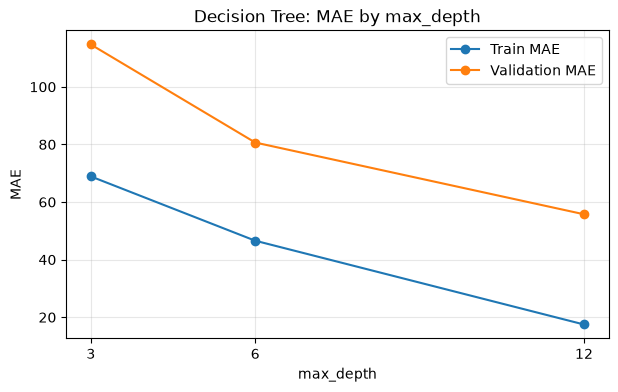

In [332]:
# [공통] 시각화 기본 설정
plt.figure(figsize=(7, 4))

# TODO 5-4. 깊이별 Train MAE와 Validation MAE를 각각 선 그래프로 표시합니다.
# 힌트: plt.plot(tree_df["max_depth"], tree_df["Train MAE"], ...)
plt.plot(
    tree_df["max_depth"],
    tree_df["Train MAE"],
    marker="o",
    label="Train MAE"
)

plt.plot(
    tree_df["max_depth"],
    tree_df["Valid MAE"],
    marker="o",
    label="Validation MAE"
)

plt.xticks(depths)
plt.xlabel("max_depth")
plt.ylabel("MAE")
plt.title("Decision Tree: MAE by max_depth")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**[CP-05]완료 기준:** 깊이 3·6·12의 성능표와 Train·Validation MAE 그래프를 완성합니다.

**선택 심화:** `min_samples_leaf` 설정을 추가로 실험합니다.

---
## ⑥ Random Forest 및 모델 통합 비교 — CP-06
**목표:** Random Forest 두 설정을 실험하고 네 종류 모델의 성능을 하나의 표로 비교합니다.

### ⑥-1. Random Forest 실험 — TODO

In [333]:
from sklearn.ensemble import RandomForestRegressor

# [공통] 비교할 두 설정
rf_configs = {
    "A": {"n_estimators": 50, "max_depth": 10},
    "B": {"n_estimators": 100, "max_depth": 15},
}
rf_models = {}

# TODO 6-1~6-2. 두 설정의 Random Forest Pipeline 학습 및 성능 수집
for key, params in rf_configs.items():
    # TODO: Pipeline 구성 (RandomForestRegressor(**params, random_state=42, n_jobs=-1))
    model = Pipeline([
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            **params,
            random_state=42,
            n_jobs=-1
        ))
    ])

    # TODO: 모델 학습
    model.fit(X_train, y_train)

    # [공통] 학습한 모델 보관
    rf_models[key] = model

    # TODO: summarize()로 결과를 results에 추가합니다.
    row = summarize(f"RandomForest_{key}", model)
    results.append(row)

### ⑥-2. 전체 성능표 비교 — TODO

In [334]:
# [공통] 지금까지 누적한 모델 결과
results_df = pd.DataFrame(results)

# TODO 6-3. Validation MAE가 낮은 순서로 정렬하고 인덱스를 정리합니다.
results_df = results_df.sort_values(
    by="Valid MAE",
    ascending=True
).reset_index(drop=True)

# TODO 6-4. Validation MAE - Train MAE를 계산합니다.
results_df["Gap (Valid-Train MAE)"] = (
    results_df["Valid MAE"] - results_df["Train MAE"]
)

display(results_df.round(3))

,Model,Train MAE,Train RMSE,Train R2,Valid MAE,Valid RMSE,Valid R2,Gap (Valid-Train MAE)
0,RandomForest_A,22.840,36.206,0.944,46.708,70.722,0.900,23.868
1,RandomForest_B,11.634,18.707,0.985,47.576,73.870,0.891,35.942
2,DecisionTree_depth_12,17.479,30.397,0.960,55.748,85.501,0.854,38.269
3,DecisionTree_depth_6,46.571,72.137,0.776,80.660,117.070,0.726,34.089
4,DecisionTree_depth_3,68.890,100.091,0.569,114.696,166.986,0.442,45.807
5,LinearRegression,68.195,89.277,0.657,114.982,145.140,0.579,46.786
6,DummyRegressor,119.572,152.400,0.000,194.518,254.607,-0.296,74.946


**[CP-06]완료 기준:** Dummy·Linear·Decision Tree·Random Forest 결과를 같은 Validation MAE 기준으로 비교합니다.

**선택 심화:** 추가 파라미터 탐색이나 시간 순서 교차검증을 시도합니다.

---
## ⑦ 오류 분석 및 최종 모델 선택 — CP-07
**목표:** 두 후보 모델의 예측 오차를 분석하고, 근거를 기록하여 최종 모델을 결정합니다.

### ⑦-1. 후보 모델과 잔차 — TODO

In [335]:
# TODO 7-1. results_df를 검토하여 오류 분석할 후보 모델 2개를 선택합니다.
# tree_models, rf_models 또는 앞서 학습한 모델 객체를 활용합니다.
candidates = {
    # "후보 이름": 학습된 모델 객체
    "RandomForest_A": rf_models["A"],
    "RandomForest_B": rf_models["B"]
}

# [공통] 실제값과 시간대 DataFrame
pred_df = pd.DataFrame({
    "hr": X_valid["hr"].values,
    "actual": y_valid.values,
})

# TODO 7-2. 각 모델의 Validation 예측값과 잔차를 계산합니다.
for name, model in candidates.items():
    pred_df[f"pred_{name}"] = model.predict(X_valid)
    pred_df[f"resid_{name}"] = (
        pred_df["actual"] - pred_df[f"pred_{name}"]
    )
display(pred_df.head())

,hr,actual,pred_RandomForest_A,resid_RandomForest_A,pred_RandomForest_B,resid_RandomForest_B
0,0,116,128.604667,-12.604667,129.885008,-13.885008
1,1,82,107.104901,-25.104901,104.054258,-22.054258
2,2,64,63.303370,0.696630,66.712769,-2.712769
3,3,31,28.452166,2.547834,28.282336,2.717664
4,4,2,9.988900,-7.988900,10.273636,-8.273636


### ⑦-2. 실제값과 예측값 시각화 — TODO

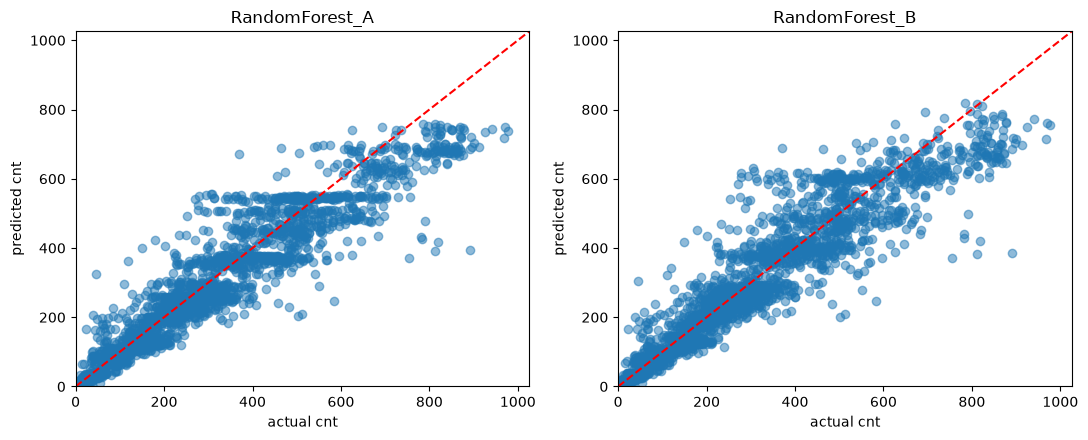

In [336]:
# [공통] 두 후보 모델을 나란히 비교합니다.
assert len(candidates) == 2, "오류 분석 후보를 2개 선택하세요."
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
lim = pred_df["actual"].max() * 1.05

for ax, name in zip(axes, candidates):
    # TODO 7-3. 실제값(x)·예측값(y) 산점도와 y=x 기준선을 작성합니다.
    # 힌트: ax.scatter(), ax.plot()
    ax.scatter(
        pred_df["actual"],
        pred_df[f"pred_{name}"],
        alpha=0.5
    )

    # y=x 기준선
    ax.plot(
        [0, lim],
        [0, lim],
        "r--",
        label="Perfect Prediction"
    )

    # [공통] 축 및 제목
    ax.set_xlabel("actual cnt")
    ax.set_ylabel("predicted cnt")
    ax.set_title(name)
    ax.set_xlim(0, lim)
    ax.set_ylim(0, lim)

plt.tight_layout()
plt.show()

### ⑦-3. 시간대별 MAE — TODO

In [337]:
# [공통] 시간대별 오류 DataFrame
hourly_mae = pd.DataFrame(index=range(24))
hourly_mae.index.name = "hr"

for name in candidates:
    # TODO 7-4. 모델별 절대오차와 시간대별 평균 절대오차를 계산합니다.
    abs_err = (
        pred_df["actual"] - pred_df[f"pred_{name}"]
    ).abs()
    hourly_mae[name] = (
        abs_err.groupby(pred_df["hr"]).mean()
    )

display(hourly_mae.round(1))

,RandomForest_A,RandomForest_B
hr,,
0,22.6,21.8
1,12.3,12.0
2,8.8,8.4
3,4.2,4.0
4,3.3,3.2
5,10.8,10.4
6,32.7,31.5
7,60.1,56.2
8,65.8,64.3


<Figure size 1200x500 with 0 Axes>

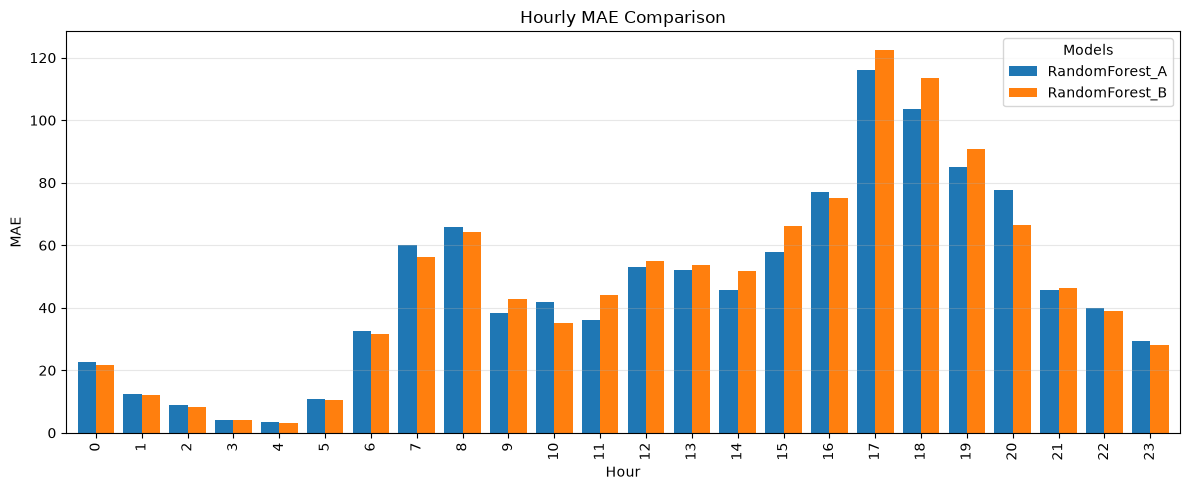

In [338]:
# TODO 7-5. 후보 모델들의 시간대별 MAE를 막대그래프로 표현합니다.
# 힌트: plt.bar(), hourly_mae
plt.figure(figsize=(12, 5))

hourly_mae.plot(
    kind="bar",
    figsize=(12, 5),
    width=0.8
)

plt.xlabel("Hour")
plt.ylabel("MAE")
plt.title("Hourly MAE Comparison")
plt.legend(title="Models")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### ⑦-4. 최종 모델 선택 — 기록

In [339]:
# **TODO 7-6:** results_df의 Validation MAE, Train·Validation 성능 차이, 예측 오류 분석 결과를 비교하여 최종 모델과 설정을 선택합니다.
# 선택한 모델과 그 근거는 adr.md의 의사결정 ②에 기록합니다.
# 선택한 모델과 설정은 ⑧교시의 최종 학습에 사용합니다.

**[CP-07] 완료 기준:** 잔차와 시간대별 MAE 분석을 완료하고 최종 모델 선택 이유를 설명합니다.

**선택 심화:** Permutation Importance로 입력 특성의 기여도를 분석합니다 (필수 아님).

In [340]:
# [선택 심화] 특성 중요도
# TODO (선택): sklearn.inspection.permutation_importance 를 사용해
# Validation 데이터에서 각 입력 특성을 섞었을 때 MAE가 얼마나 변하는지 분석합니다.
# 이 셀을 실행하지 않아도 ⑧교시 진행에 영향이 없습니다.

---
## ⑧ 최종 모델 완성 및 예측 — CP-08
**목표:** 선택한 모델을 재학습하고 Test 평가, 모델 저장·재로딩, 입력 한 건 예측까지 구현합니다.

### ⑧-1. 최종 모델 재학습 — TODO

In [351]:
import joblib
from pathlib import Path

# [공통] Train과 Validation 데이터 결합
X_trainval = pd.concat([X_train, X_valid])
y_trainval = pd.concat([y_train, y_valid])

# TODO 8-1. ⑦에서 선택한 모델과 하이퍼파라미터로 새 estimator를 생성합니다.
# 예: 앞서 사용한 회귀 모델 클래스와 선택한 설정을 사용합니다.
final_estimator = RandomForestRegressor(
    n_estimators=50,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

# [공통] 최종 Pipeline은 전처리를 포함해야 합니다.
final_model = Pipeline([
    ("prep", make_preprocessor()),
    ("model", final_estimator),
])

# TODO 8-2. Train + Validation으로 최종 모델을 재학습합니다.
final_model.fit(X_trainval, y_trainval)

print("최종 모델 학습 완료")

최종 모델 학습 완료


### ⑧-2. Test 평가 — TODO

In [342]:
# TODO 8-3. Test 데이터에 대해 최종 MAE·RMSE·R2를 평가합니다.
# ④에서 작성한 evaluate_regression()을 재사용합니다.
test_scores = evaluate_regression(final_model, X_test, y_test)
print("최종 Test 성능:", test_scores)

최종 Test 성능: {'MAE': 56.24193952687459, 'RMSE': 84.46458874938355, 'R2': 0.8446006903449182}


### ⑧-3. 최종 모델 저장과 재로딩 — TODO

In [343]:
# [공통] 결과 폴더와 저장 경로
RESULTS_DIR = Path("../results")
RESULTS_DIR.mkdir(exist_ok=True)
MODEL_PATH = RESULTS_DIR / "01_final_model.joblib"

# TODO 8-4. 전처리+모델 Pipeline을 joblib으로 저장합니다 (compress=3).
joblib.dump(final_model, MODEL_PATH, compress=3)

# TODO 8-5. 저장된 Pipeline을 다시 불러옵니다.
loaded_model = joblib.load(MODEL_PATH)

# TODO 8-6. 저장 전후 예측 결과가 일치하는지 확인합니다.
# 힌트: np.allclose(), X_test.iloc[:100]
same_pred = np.allclose(
    final_model.predict(X_test.iloc[:100]),
    loaded_model.predict(X_test.iloc[:100])
)
print("저장 전후 예측 일치:", same_pred)

저장 전후 예측 일치: True


In [344]:
# [공통] 실험 결과표 저장
results_df.round(3).to_csv(
    RESULTS_DIR / "01_model_comparison.csv", index=False
)
hourly_mae.round(2).to_csv(
    RESULTS_DIR / "01_hourly_mae_validation.csv"
)
print("결과 파일:", sorted(p.name for p in RESULTS_DIR.iterdir()))

결과 파일: ['01_final_model.joblib', '01_hourly_mae_validation.csv', '01_model_comparison.csv']


### ⑧-4. 단일 입력 예측 함수 — TODO

In [345]:
def predict_demand(
    model, season, yr, mnth, hr, holiday,
    weekday, workingday, weathersit, temp, atemp, hum, windspeed
):
    """한 시간의 입력 조건으로 예상 대여량(정수)을 반환합니다.

    temp, hum, windspeed는 hour.csv와 같은 정규화 값(0~1)으로 입력합니다.
    """
    # TODO 8-7. 전달받은 값으로 입력 1행 DataFrame을 만듭니다.
    # 학습에 사용한 FEATURES 컬럼을 정확히 사용해야 합니다.
    row = pd.DataFrame([{
        "season": season,
        "yr": yr,
        "mnth": mnth,
        "hr": hr,
        "holiday": holiday,
        "weekday": weekday,
        "workingday": workingday,
        "weathersit": weathersit,
        "temp": temp,
        "atemp": atemp,
        "hum": hum,
        "windspeed": windspeed
    }])

    # TODO 8-8. ③에서 만든 동일한 특성공학 함수를 적용합니다.
    row = add_commute_feature(row)

    # TODO 8-9. 예측값 하나를 구해 정수로 반환합니다.
    pred = model.predict(row)[0]

    return int(round(pred))


# [공통] 섭씨 온도를 원본 데이터의 정규화 기온으로 변환
def celsius_to_temp(c):
    return (c + 8) / 47


# [공통] 예측 입력 예제
sample = {
    "season": 4,
    "yr": 1,
    "mnth": 10,
    "hr": 18,
    "holiday": 0,
    "weekday": 3,
    "workingday": 1,
    "weathersit": 1,
    "temp": celsius_to_temp(20),
    "atemp": celsius_to_temp(20),  # 추가
    "hum": 0.50,
    "windspeed": 0.15,
}

# TODO 8-10. 저장한 모델과 sample을 사용해 predict_demand()를 호출합니다.
# 힌트: predict_demand(loaded_model, **sample)
result = predict_demand(loaded_model, **sample)
print("예상 대여량:", result)

예상 대여량: 746


**[CP-08] 완료 기준 :** 최종 재학습·Test 평가·모델 저장·재로딩·예측 함수가 정상 동작하면 프로젝트 코드가 완성됩니다.